# Loading a cosmological simulation

A quickstart guide to loading the simulation

In [1]:
import yt
import unyt
from astropy.table import Table
import helper_functions as hf
import numpy as np
import matplotlib.pyplot as plt
import se_functions
import importlib

importlib.reload(se_functions)
from se_functions import find_bursts

In [2]:
final_output=116

# Load the timeseries of the most massive black hole

In [3]:
df='/lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine'

In [4]:
# Load position from file and count BH
filename=f'{df}/output_{str(final_output).zfill(5)}/sink_{str(final_output).zfill(5)}.csv'
t = Table.read(filename,format='ascii',names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])
print("This output contains",len(t),"black holes")
order=np.argsort(t['BHmass'])[::-1]
second_id=t['sink_id'][order[1]]
most_massive_id=t['sink_id'][np.argmax(t['BHmass'])]
print("The most massive BH has id",most_massive_id)
print("The second most massive BH has id", second_id)

This output contains 684 black holes
The most massive BH has id 5
The second most massive BH has id 36


# Plot evolution of most massive BH

In [5]:
# Load timeseries for most massive black hole
ts=hf.SinkDataLoader(df,sinkid=most_massive_id)

for c in ts.data.colnames:
    print(c, ts.data[c].unit, ts.data[c].shape)

nstep None (137040,)
aexp None (137040,)
time Gyr (137040,)
BHmass solMass (137040,)
position pc (137040, 3)
vsink km / s (137040, 3)
dotMbondi solMass / yr (137040,)
dotMedd solMass / yr (137040,)
rg_scale pc (137040,)
spinmag None (137040,)
dMgrowth solMass (137040,)
dMaccr solMass (137040,)
Esave erg (137040,)
bhspin None (137040, 3)
jsink None (137040, 3)
Efeed erg (137040,)
f_edd None (137040,)
eps_sink None (137040,)
eta_disk None (137040,)
eta_jet None (137040,)
Mass_loading_factor None (137040,)
Rb pc (137040,)
Ra pc (137040,)
Rbhl pc (137040,)
Rbhl_cell pc (137040,)
Ra_cell pc (137040,)
Rb_cell pc (137040,)
dtnew yr (137040,)
dotMgrowth solMass / yr (137040,)
dotMaccr solMass / yr (137040,)
Efeed_Th erg (137040,)
Efeed_Ki erg (137040,)
alpha_madau None (137040,)
beta_eff None (137040,)
z None (137040,)


In [6]:
time=Table.read(df+'/ADAPTAclump_maps/output_step_redshift.txt',format='ascii')

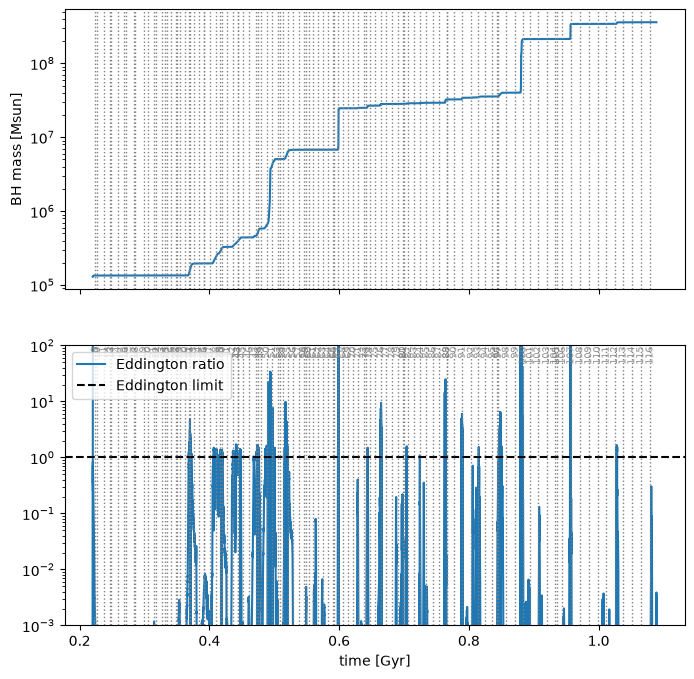

In [7]:
# Full timeseries
fig,axes=plt.subplots(2,1,figsize=(8,8),sharex=True)

# Time window to display (Gyr)
# Edit these values to change the plotted time range
tmin=ts.data['time'][0]  # Start time (Gyr)
tmax=ts.data['time'][-1]  # End time (Gyr)

#tmin = 0.365 #Comment out for whole timeseries
#tmax = 0.38  # Comment out for whole timeseries

# Plot mass (only inside [tmin,tmax])
ax = axes[0]
times = ts.data['time']
mask = (times >= tmin) & (times <= tmax)
ax.plot(times[mask], ts.data['BHmass'][mask], label='BH mass')
ax.set_yscale('log')
ax.set_ylabel('BH mass [Msun]')

# Plot Eddington ratios (only inside [tmin,tmax])
ax = axes[1]
ratio = ts.data['dotMaccr']/ts.data['dotMedd']
ax.plot(times[mask], ratio[mask], label='Eddington ratio')
ax.axhline(1.0, ls='--', color='k', label='Eddington limit')
ax.set_yscale('log')
ax.legend()

# Add output times and redshifts
axes[-1].set_xlabel('time [Gyr]')

# Draw vertical dotted grey lines at each output time from the `time` table (ensure units are Gyr)
try:
    # If `time` is an astropy Table with a column 'time' that may have units
    output_times = time['time']
    # If entries are yt or unyt quantities, convert to float in Gyr
    try:
        output_times_gyr = [t.to('Gyr').v if hasattr(t,'to') else float(t) for t in output_times]
    except Exception:
        # Fallback: assume column already in Gyr or plain numbers
        output_times_gyr = [float(t) for t in output_times]

    # Assume the table has an `output` column containing integer output numbers
    outputs = [int(o) for o in time['output']]
    outputs_labels = [str(o) for o in outputs]
    axes[-1].set_ylim([1e-3,1e2])

    # Draw lines and small grey rotated labels aligned with the vertical lines
    ymin0, ymax0 = axes[0].get_ylim()
    ymin1, ymax1 = axes[1].get_ylim()
    # place labels near the top of the lower subplot (axes[1])
    label_y = ymax1 * 0.95

    # Only show output lines/labels that fall inside [tmin, tmax]
    visible = [(ot, lbl) for ot, lbl in zip(output_times_gyr, outputs_labels) if (ot >= tmin and ot <= tmax)]
    for ot, lbl in visible:
        axes[0].axvline(ot, color='grey', linestyle=':', linewidth=1)
        axes[1].axvline(ot, color='grey', linestyle=':', linewidth=1)
        axes[1].text(ot, label_y, lbl, color='grey', fontsize=7, rotation=90, va='top', ha='center', alpha=0.8)
except Exception as e:
    print('Could not draw output-time vertical lines and labels:', e)

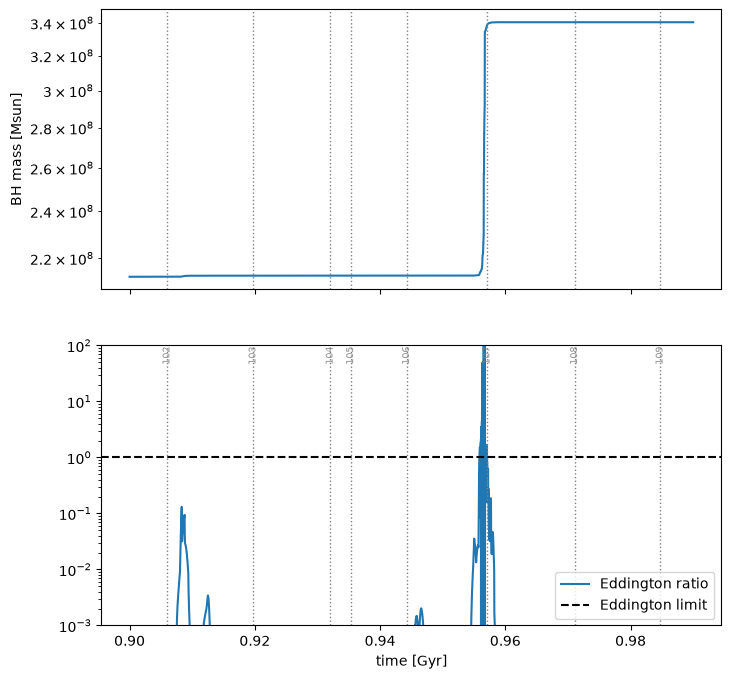

In [8]:
# Full timeseries
fig,axes=plt.subplots(2,1,figsize=(8,8),sharex=True)

# Time window to display (Gyr)
# Edit these values to change the plotted time range
tmin=ts.data['time'][0]  # Start time (Gyr)
tmax=ts.data['time'][-1]  # End time (Gyr)

# For the most massive BH
tmin = 0.90  #Comment out for whole timeseries
tmax = 0.99  # Comment out for whole timeseries


# For the second massive BH
# tmin = 0.53
# tmax = 0.58


# Plot mass (only inside [tmin,tmax])
ax = axes[0]
times = ts.data['time']
mask = (times >= tmin) & (times <= tmax)
ax.plot(times[mask], ts.data['BHmass'][mask], label='BH mass')
ax.set_yscale('log')
ax.set_ylabel('BH mass [Msun]')

# Plot Eddington ratios (only inside [tmin,tmax])
ax = axes[1]
ratio = ts.data['dotMaccr']/ts.data['dotMedd']
ax.plot(times[mask], ratio[mask], label='Eddington ratio')
ax.axhline(1.0, ls='--', color='k', label='Eddington limit')
ax.set_yscale('log')
ax.legend()

# Add output times and redshifts
axes[-1].set_xlabel('time [Gyr]')

# Draw vertical dotted grey lines at each output time from the `time` table (ensure units are Gyr)
try:
    # If `time` is an astropy Table with a column 'time' that may have units
    output_times = time['time']
    # If entries are yt or unyt quantities, convert to float in Gyr
    try:
        output_times_gyr = [t.to('Gyr').v if hasattr(t,'to') else float(t) for t in output_times]
    except Exception:
        # Fallback: assume column already in Gyr or plain numbers
        output_times_gyr = [float(t) for t in output_times]

    # Assume the table has an `output` column containing integer output numbers
    outputs = [int(o) for o in time['output']]
    outputs_labels = [str(o) for o in outputs]
    axes[-1].set_ylim([1e-3,1e2])

    # Draw lines and small grey rotated labels aligned with the vertical lines
    ymin0, ymax0 = axes[0].get_ylim()
    ymin1, ymax1 = axes[1].get_ylim()
    # place labels near the top of the lower subplot (axes[1])
    label_y = ymax1 * 0.95

    # Only show output lines/labels that fall inside [tmin, tmax]
    visible = [(ot, lbl) for ot, lbl in zip(output_times_gyr, outputs_labels) if (ot >= tmin and ot <= tmax)]
    for ot, lbl in visible:
        axes[0].axvline(ot, color='grey', linestyle=':', linewidth=1)
        axes[1].axvline(ot, color='grey', linestyle=':', linewidth=1)
        axes[1].text(ot, label_y, lbl, color='grey', fontsize=7, rotation=90, va='top', ha='center', alpha=0.8)
except Exception as e:
    print('Could not draw output-time vertical lines and labels:', e)

# Generate super-Eddington Catalogue

In [9]:
b = find_bursts(ts.data, gap_myr=0.1, min_dur_myr=0.001)
print(len(b))
b.sort('dM_accr', reverse=True)
b[:10]

29


i_start,i_end,t_start_myr,t_end_myr,duration_myr,z_start,z_end,aexp_start,aexp_end,M_start,M_end,dM_accr,E_feed,E_feed_Th,E_feed_Ki,f_edd_max,dM_edd_max
int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
117487,117584,956.0860413212562,956.7077190206932,0.6216776994369866,5.897902595968379,5.894907205808491,0.144971603481973,0.145034584244668,214759362.769388,334417707.541136,119748870.9633568,0.0,0.0,0.0,3.83838606356281,649.5513805357821
104913,105137,879.4224635152748,880.7104377432252,1.2879742279503716,6.294033342342375,6.286906477354737,0.13709835876331,0.137232446046572,40061966.8857575,136056580.748092,96004970.04436493,3.308177839150908e+54,3.308177839150908e+54,2.9718200605047242e+51,3.67333976063487,352.1526323407555
105173,105310,880.9090989668093,881.6957289744914,0.7866300076821062,6.2858087508550256,6.281466174024259,0.137253122363752,0.137334978437087,136828518.943607,200660362.409837,63884438.51925766,0.0,0.0,0.0,3.79799344535509,546.1231753314818
47654,47925,598.2585171743991,599.345849576729,1.0873324023299347,8.433170092523143,8.42174728838957,0.106008901587878,0.106137425404341,6803587.42468251,24227577.3769659,17425865.282091904,1.884914340805533e+58,1.927498723410617e+54,5.88943945598337e+55,3.6979143973799,379.1260881593993
105419,105459,882.3143342596935,882.5321592318293,0.2178249721357588,6.278055700668018,6.276855742597291,0.137399333163693,0.137421990399809,205443678.545633,208846529.808029,3462383.3950023446,0.0,0.0,0.0,2.72608566119658,41.78784786285182
26405,26851,490.259899491131,494.18032043814975,3.9204209470187266,9.773133025861881,9.716046056237632,0.092823508036094,0.093318001318025,687787.906619867,3713087.43874647,3025688.577485166,8.746308396698397e+58,1.3632527371667035e+55,3.068199760426602e+52,2.63166456419417,33.92864688244531
85327,85390,763.5101696174208,763.9140908144674,0.40392119704654306,7.016018038130156,7.013187999287915,0.124750218280854,0.124794276646057,29408256.7441269,31575148.7130367,2177913.3705843817,0.0,0.0,0.0,2.49271947817475,24.836162153428482
117615,117633,956.9049570312785,957.026804663174,0.12184763189543446,5.893957542982986,5.893371032941344,0.145054563183066,0.145066904888958,336006564.791875,337850086.401789,1979351.5398360793,0.0,0.0,0.0,1.05486429053964,1.6695858861601434
105333,105365,881.8280165207647,881.9995072169905,0.17149069622587376,6.280736516230585,6.279790896880528,0.137348741816264,0.137366582936951,201821613.636362,203463223.717851,1698949.3002466029,0.0,0.0,0.0,1.38099627038601,2.830825677592344


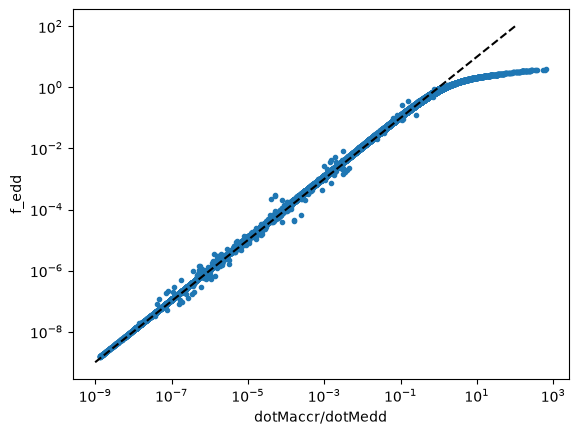

In [29]:
ratio = ts.data['dotMaccr'] / ts.data['dotMedd']
m = ratio > 0
plt.loglog(ratio[m], ts.data['f_edd'][m], ".")
plt.plot([1e-9, 1e2], [1e-9, 1e2], 'k--')
plt.xlabel('dotMaccr/dotMedd')
plt.ylabel('f_edd');

# Load a dataset

In [16]:
output=107

In [17]:
ds=yt.load(hf.info_file(output,df))

print(ds.field_list)
print(ds.particle_types)

print(ds.parameters['levelmax'])
# print(ds.index.get_smallest_dx().in_units('pc'))
# print(ds.index.get_smallest_dx().in_units('pccm'))

# ds.field_list
# ds.derived_field_list

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00107/info_00107.txt


yt : [INFO     ] 2026-10-16 12:27:36,567 Parameters: current_time              = 0.957073815898591 Gyr
yt : [INFO     ] 2026-10-16 12:27:36,568 Parameters: domain_dimensions         = [128 128 128]
yt : [INFO     ] 2026-10-16 12:27:36,569 Parameters: domain_left_edge          = [0. 0. 0.]
yt : [INFO     ] 2026-10-16 12:27:36,569 Parameters: domain_right_edge         = [1. 1. 1.]
yt : [INFO     ] 2026-10-16 12:27:36,570 Parameters: cosmological_simulation   = True
yt : [INFO     ] 2026-10-16 12:27:36,571 Parameters: current_redshift          = 5.893144758947767
yt : [INFO     ] 2026-10-16 12:27:36,571 Parameters: omega_lambda              = 0.693499982357025
yt : [INFO     ] 2026-10-16 12:27:36,573 Parameters: omega_matter              = 0.306499987840652
yt : [INFO     ] 2026-10-16 12:27:36,573 Parameters: omega_radiation           = 0.0
yt : [INFO     ] 2026-10-16 12:27:36,574 Parameters: hubble_constant           = 0.6790000152587891
yt : [WARNING  ] 2026-10-16 12:27:38,028 The DM pa

[('gravity', 'Potential'), ('gravity', 'x-acceleration'), ('gravity', 'y-acceleration'), ('gravity', 'z-acceleration'), ('io', 'conformal_birth_time'), ('io', 'particle_birth_time'), ('io', 'particle_family'), ('io', 'particle_identity'), ('io', 'particle_level'), ('io', 'particle_mass'), ('io', 'particle_metallicity'), ('io', 'particle_position_x'), ('io', 'particle_position_y'), ('io', 'particle_position_z'), ('io', 'particle_tag'), ('io', 'particle_velocity_x'), ('io', 'particle_velocity_y'), ('io', 'particle_velocity_z'), ('nbody', 'particle_birth_time'), ('nbody', 'particle_mass'), ('nbody', 'particle_position_x'), ('nbody', 'particle_position_y'), ('nbody', 'particle_position_z'), ('nbody', 'particle_velocity_x'), ('nbody', 'particle_velocity_y'), ('nbody', 'particle_velocity_z'), ('ramses', 'Density'), ('ramses', 'Metallicity'), ('ramses', 'Pressure'), ('ramses', 'hydro_scalar_01'), ('ramses', 'x-velocity'), ('ramses', 'y-velocity'), ('ramses', 'z-velocity'), ('sink', 'BH_bondi_

In [13]:
ad=ds.all_data() # Load a data object that contains all data

print(np.unique(ad['DM', 'particle_mass'].to('Msun')))

yt : [INFO     ] 2026-10-14 20:23:52,476 Identified   512/  512 intersecting domains (  512 through hilbert key indexing)


[3.02381259e+06 2.41905007e+07 1.93524006e+08 1.54819205e+09
 1.23855364e+10 9.90842911e+10 7.92674328e+11 6.34139463e+12] Msun


In [14]:
print("The current redshift is",ds.current_redshift) #Load some information on the output


The current redshift is 6.4184959165479745


In [15]:
print("The whole box has a size of",ds.length_unit.in_units('Mpc'))

The whole box has a size of 99.07966580046096 Mpc


# Plot the whole box and annotate black holes

yt : [INFO     ] 2026-10-14 20:25:06,933 Projection completed
yt : [INFO     ] 2026-10-14 20:25:06,940 xlim = 0.000000 1.000000
yt : [INFO     ] 2026-10-14 20:25:06,940 ylim = 0.000000 1.000000
yt : [INFO     ] 2026-10-14 20:25:06,943 xlim = 0.000000 1.000000
yt : [INFO     ] 2026-10-14 20:25:06,943 ylim = 0.000000 1.000000
yt : [INFO     ] 2026-10-14 20:25:06,946 Making a fixed resolution buffer of (('gas', 'density')) 800 by 800
yt : [INFO     ] 2026-10-14 20:25:09,307 Identified   512/  512 intersecting domains (  512 through hilbert key indexing)



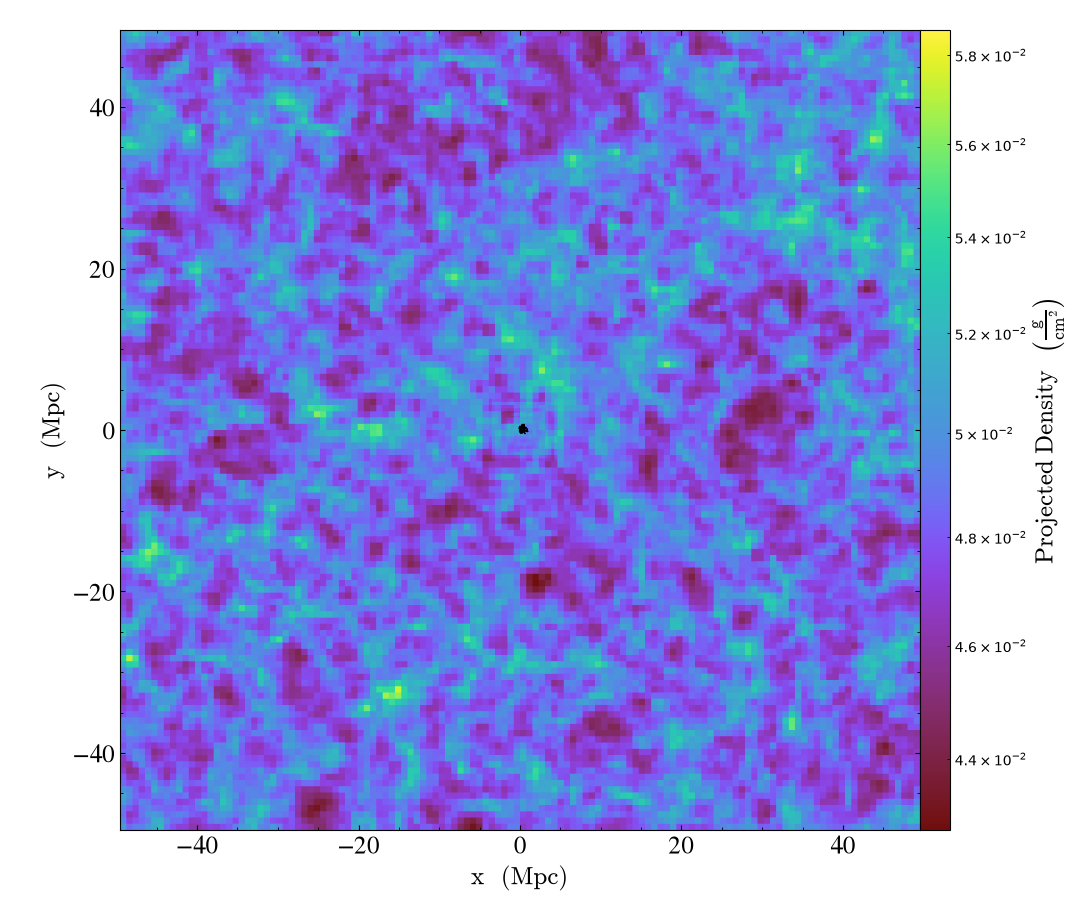

In [16]:
p=yt.ProjectionPlot(ds,normal='z',fields=['density'])
p.annotate_particles(width=ds.length_unit,ptype='sink')
p.show()

# Plot central 1 Mpc and annotate BH

yt : [INFO     ] 2026-10-14 20:25:26,239 Identified   492/  512 intersecting domains (  503 through hilbert key indexing)
yt : [INFO     ] 2026-10-14 20:25:36,111 Projection completed
yt : [INFO     ] 2026-10-14 20:25:36,113 xlim = 0.494954 0.505046
yt : [INFO     ] 2026-10-14 20:25:36,113 ylim = 0.494954 0.505046
yt : [INFO     ] 2026-10-14 20:25:36,115 xlim = 0.494954 0.505046
yt : [INFO     ] 2026-10-14 20:25:36,116 ylim = 0.494954 0.505046
yt : [INFO     ] 2026-10-14 20:25:36,117 Making a fixed resolution buffer of (('gas', 'density')) 800 by 800
yt : [INFO     ] 2026-10-14 20:25:38,915 Identified   440/  512 intersecting domains (  503 through hilbert key indexing)



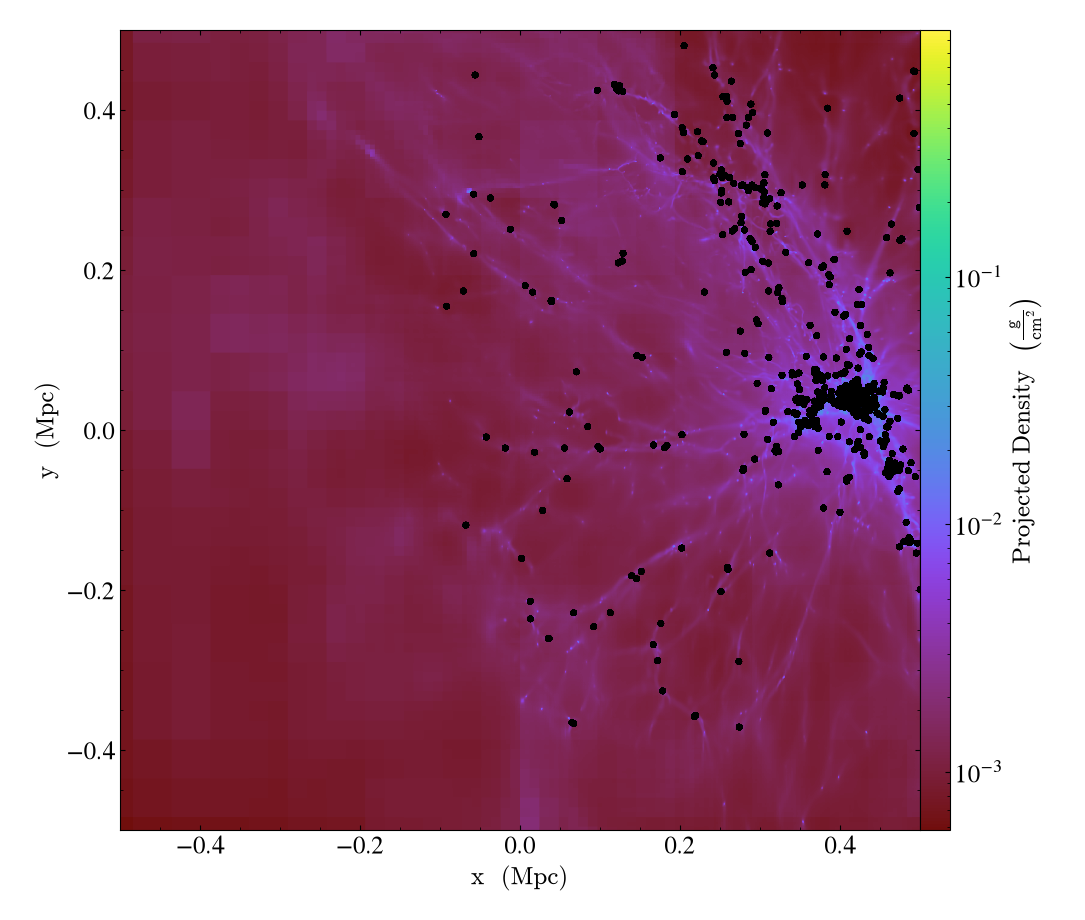

In [17]:
width=ds.quan(1,'Mpc')  #Width of your plot
region=ds.sphere(ds.arr([0.5,0.5,0.5],'code_length'),width) # Make a sphere with the data you want to plot
p=yt.ProjectionPlot(ds,normal='z',fields=['density'],width=width,data_source=region)
p.annotate_particles(width=width*2,ptype='cloud',data_source=region,p_size=15)
p.show()

# Center plot on sink number 5

In [18]:
target_sink=5

In [19]:
# Load position from file at this output
filename=f'{df}/output_{str(output).zfill(5)}/sink_{str(output).zfill(5)}.csv'
t = Table.read(filename,format='ascii',names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])
print("This output contains",len(t),"black holes")

This output contains 671 black holes


In [20]:
# Find position of target BH
sink_pos=t[t['sink_id']==target_sink]['x','y','z'] # Position on 6th sink
sink_pos_ds=ds.arr(sink_pos[0].as_void().tolist(),'code_length') #Position converted to something the dataset understands by adding units and stripping formatting

yt : [INFO     ] 2026-10-16 12:22:16,805 Identified   447/  512 intersecting domains (  447 through hilbert key indexing)
yt : [INFO     ] 2026-10-16 12:23:13,649 Projection completed
yt : [INFO     ] 2026-10-16 12:23:13,658 xlim = 0.502710 0.505549
yt : [INFO     ] 2026-10-16 12:23:13,659 ylim = 0.499030 0.501869
yt : [INFO     ] 2026-10-16 12:23:13,663 xlim = 0.502710 0.505549
yt : [INFO     ] 2026-10-16 12:23:13,663 ylim = 0.499030 0.501869
yt : [INFO     ] 2026-10-16 12:23:13,668 Making a fixed resolution buffer of (('gas', 'density')) 800 by 800
yt : [INFO     ] 2026-10-16 12:23:14,879 Identified   156/  512 intersecting domains (  222 through hilbert key indexing)



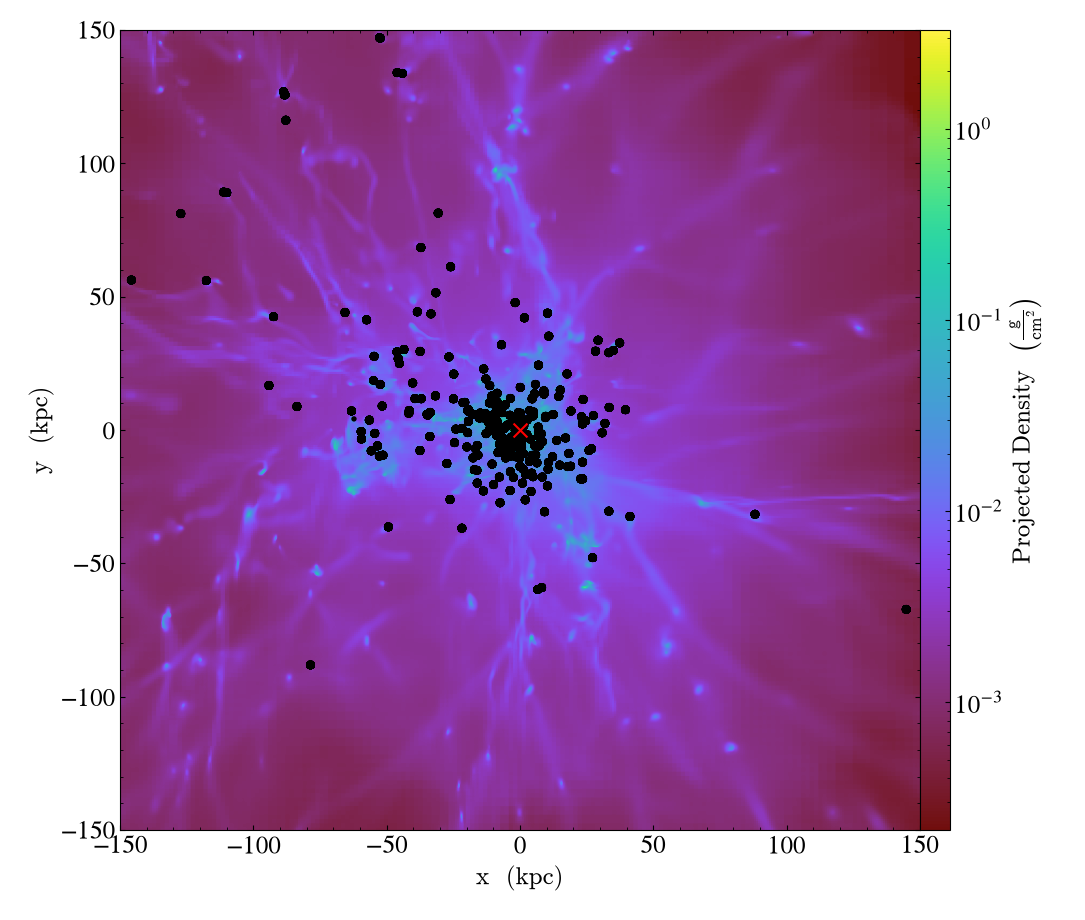

In [15]:
# Make plot centred on BH 17, zooming in to the central 300 kpc
width=ds.quan(300,'kpc')  #Width of your plot
region=ds.sphere(sink_pos_ds,width) # Make a sphere with the data you want to plot
p=yt.ProjectionPlot(ds,normal='z',fields=['density'],width=width,data_source=region,center=sink_pos_ds)
p.annotate_particles(width=width.in_units('code_length'),ptype='cloud',data_source=region,p_size=15)
p.annotate_marker(region.center, coord_system='data', color='red', s=100)

p.show()

yt : [INFO     ] 2026-10-16 12:27:56,634 Identified    65/  512 intersecting domains (   65 through hilbert key indexing)
yt : [INFO     ] 2026-10-16 12:27:59,754 Projection completed
yt : [INFO     ] 2026-10-16 12:27:59,755 xlim = 0.503990 0.504178
yt : [INFO     ] 2026-10-16 12:27:59,756 ylim = 0.500369 0.500556
yt : [INFO     ] 2026-10-16 12:27:59,759 xlim = 0.503990 0.504178
yt : [INFO     ] 2026-10-16 12:27:59,759 ylim = 0.500369 0.500556
yt : [INFO     ] 2026-10-16 12:27:59,762 Making a fixed resolution buffer of (('gas', 'density')) 800 by 800



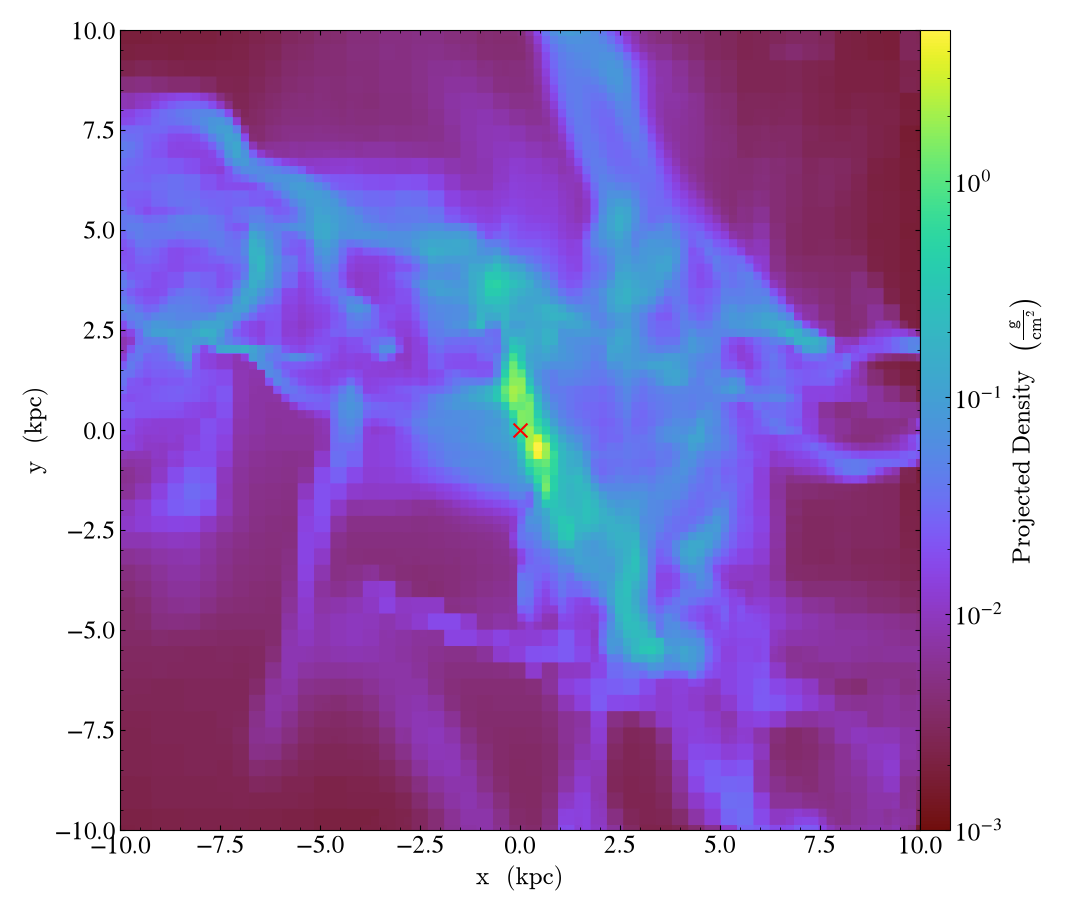

In [21]:
# Make plot centred on BH 17, zooming in to the central 10 kpc
width = ds.quan(20, 'kpc')  # Width of your plot
region = ds.sphere(sink_pos_ds, width)  # Make a sphere with the data you want to plot
p = yt.ProjectionPlot(ds, normal='z', fields=['density'], width=width, data_source=region, center=sink_pos_ds)
p.annotate_marker(region.center, coord_system='data', color='red', s=100)
p.set_zlim(('gas','density'), 1e-3, 5)

# p.save(f'fig/most_massive/density_density_{output:03d}_{width.value}.png')
p.show()

yt : [INFO     ] 2026-10-16 12:28:07,850 Identified    38/  512 intersecting domains (   65 through hilbert key indexing)
yt : [INFO     ] 2026-10-16 12:28:08,607 Projection completed
yt : [INFO     ] 2026-10-16 12:28:08,608 xlim = 0.503990 0.504178
yt : [INFO     ] 2026-10-16 12:28:08,608 ylim = 0.500369 0.500556
yt : [INFO     ] 2026-10-16 12:28:08,612 xlim = 0.503990 0.504178
yt : [INFO     ] 2026-10-16 12:28:08,612 ylim = 0.500369 0.500556
yt : [INFO     ] 2026-10-16 12:28:08,614 Making a fixed resolution buffer of (('gas', 'temperature')) 800 by 800



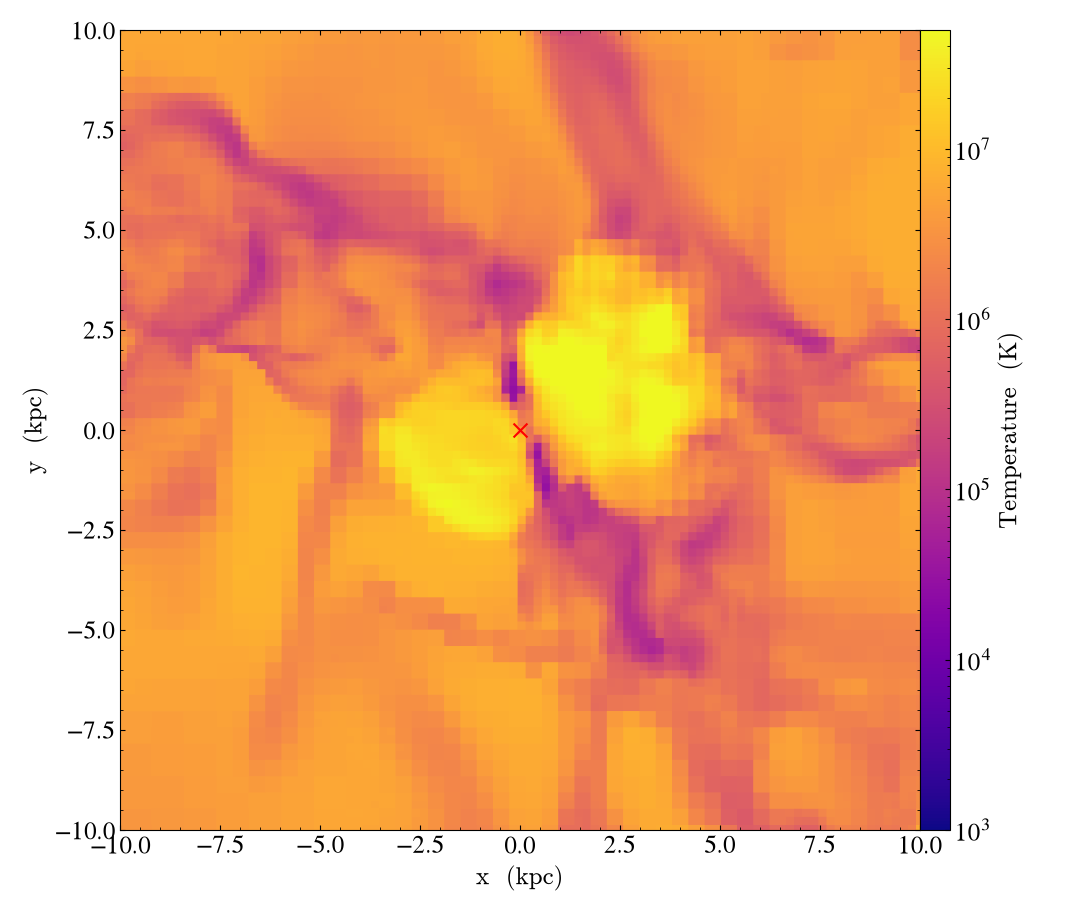

In [22]:
# Plot temperature instead, reusing the data objects
width=ds.quan(20,'kpc')
region=ds.sphere(sink_pos_ds,width) # Make a sphere with the data you want to plot
p=yt.ProjectionPlot(ds,normal='z',fields=['temperature'], weight_field=('gas','density'),
width=width,data_source=region,center=sink_pos_ds)
p.annotate_marker(region.center, coord_system='data', color='red', s=100)
p.set_cmap('temperature', 'plasma')
p.set_zlim('temperature', 1e3, 5e7)

# p.save(f'fig/most_massive/tem_density_{output:03d}_{width.value}.png')
p.show()

In [24]:
sp = ds.sphere(sink_pos_ds, (5, 'kpc'))
E_th = (1.5 * sp['gas','pressure'] * sp['gas','cell_volume']).sum().to('erg')
print(E_th)

# 6.786206708326559e+56 erg for snapshot 099
# 7.676195514036063e+57 erg for snapshot 100

yt : [INFO     ] 2026-10-14 20:25:59,533 Identified    11/  512 intersecting domains (   23 through hilbert key indexing)


1.525823348474118e+57 erg


yt : [INFO     ] 2026-10-14 20:25:59,570 Identified 1 intersecting domains
yt : [INFO     ] 2026-10-14 20:26:00,010 Projection completed
yt : [INFO     ] 2026-10-14 20:26:00,012 xlim = 0.504075 0.504277
yt : [INFO     ] 2026-10-14 20:26:00,012 ylim = 0.500306 0.500508
yt : [INFO     ] 2026-10-14 20:26:00,015 xlim = 0.504075 0.504277
yt : [INFO     ] 2026-10-14 20:26:00,015 ylim = 0.500306 0.500508
yt : [INFO     ] 2026-10-14 20:26:00,016 Making a fixed resolution buffer of (('deposit', 'star_cic')) 800 by 800



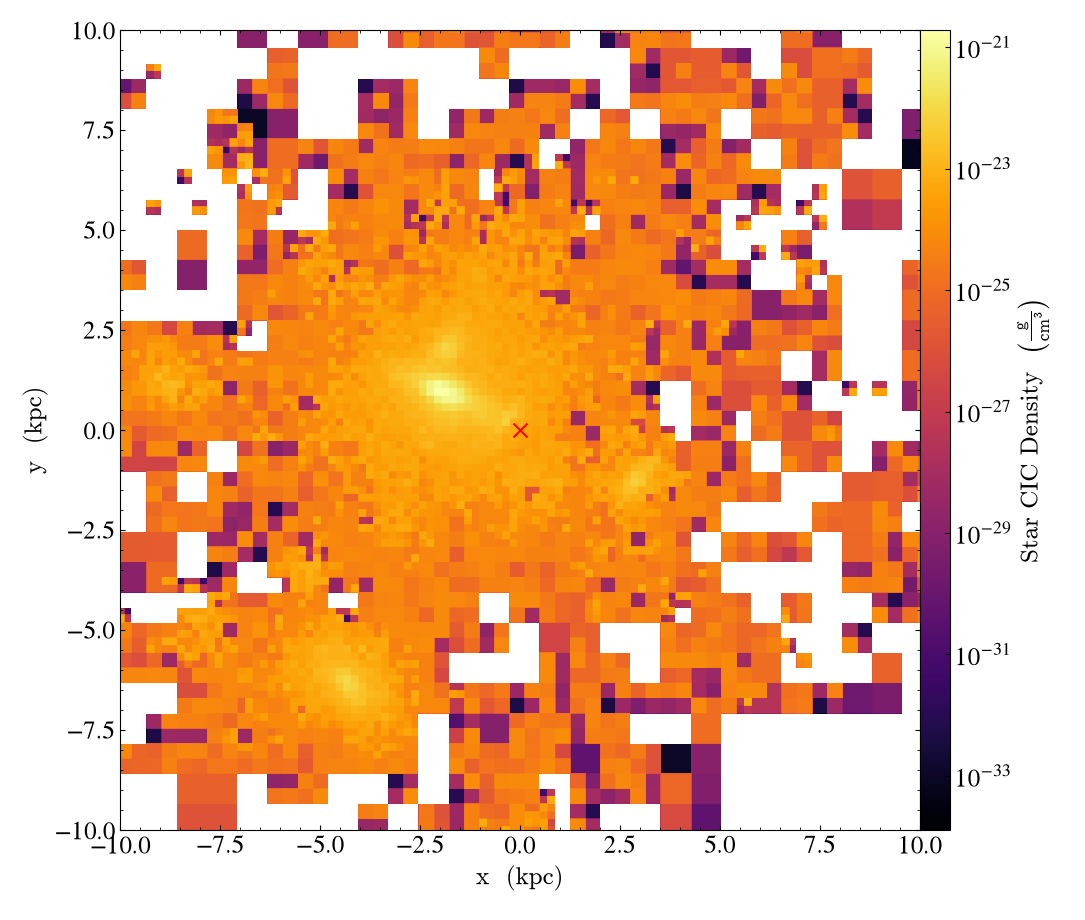

In [25]:
# Plot stellar distribution instead, reusing the data objects
field=('deposit','star_cic')
p = yt.ProjectionPlot(ds, normal='z', fields=[field],
                      width=width, data_source=region, 
                      center=sink_pos_ds,weight_field=field)
p.annotate_marker(region.center, coord_system='data', color='red', s=100)

# Use inferno colormap for the stellar field
p.set_cmap(field, 'inferno')

p.show()

# Measure gas properties within 1 kpc of sink 

In [26]:
sp=ds.sphere(sink_pos_ds,ds.quan(2,'kpc')) # Make a sphere with the data you want to plot
print("Maximum density within 2 kpc of sink 6:",sp['density'].max().in_units('g/cm**3'))
print("Maximum temperature within 2 kpc of sink 6:",sp['temperature'].max())
print("Total gas mass within 2 kpc of the sink",sp['mass'].sum().in_units('Msun'))

yt : [INFO     ] 2026-10-14 20:26:00,501 Identified     2/  512 intersecting domains (    6 through hilbert key indexing)


Maximum density within 2 kpc of sink 6: 4.968823707331805e-23 g/cm**3
Maximum temperature within 2 kpc of sink 6: 15219741.750834495 K
Total gas mass within 2 kpc of the sink 645714360.6570529 Msun


In [27]:
print("Maximum stellar mass in this sphere is",sp['star','particle_mass'].in_units('Msun').max())

Maximum stellar mass in this sphere is 1389473.8454110492 Msun


yt : [INFO     ] 2026-10-14 20:26:00,563 Identified    23/  512 intersecting domains (   32 through hilbert key indexing)


yt : [INFO     ] 2026-10-14 20:26:00,651 Projection completed
yt : [INFO     ] 2026-10-14 20:26:00,653 xlim = 0.504125 0.504226
yt : [INFO     ] 2026-10-14 20:26:00,653 ylim = 0.500357 0.500458
yt : [INFO     ] 2026-10-14 20:26:00,656 xlim = 0.504125 0.504226
yt : [INFO     ] 2026-10-14 20:26:00,656 ylim = 0.500357 0.500458
yt : [INFO     ] 2026-10-14 20:26:00,657 Making a fixed resolution buffer of (('gas', 'density')) 800 by 800



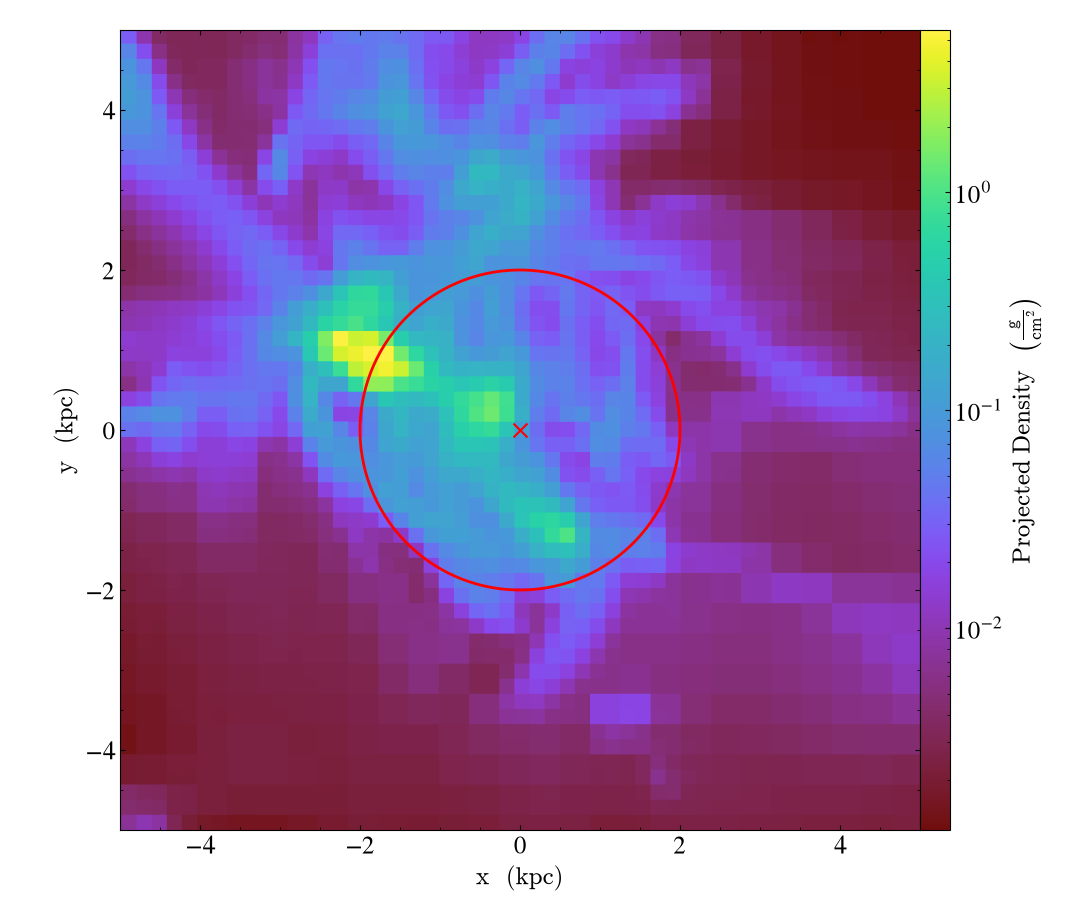

In [28]:
# Make plot centred on BH 17, zooming in to the central 10 kpc
width=ds.quan(10,'kpc')  #Width of your plot
region=ds.sphere(sink_pos_ds,width) # Make a sphere with the data you want to plot
p=yt.ProjectionPlot(ds,normal='z',fields=['density'],width=width,data_source=region,center=sink_pos_ds)
p.annotate_marker(region.center, coord_system='data', color='red', s=100)

# Annotate the sphere `sp` using yt's native annotation (handles coordinates/radius)
# Draw an unfilled red circle corresponding to the sphere projection
# pass styling via `circle_args` dict
p.annotate_sphere(sp.center, sp.radius, coord_system='data', circle_args={'color': 'red',  'linewidth': 2})

p.show()